# Chapter 47: What is not here

Checks [chapter 47](../../book/47-what-is-not-here.md). There is no model here, and nothing is measured: the notebook reads the text of chapters 1 to 46 and counts how often each of the labels `**proved**`, `**measured**`, `**argued**`, `**open**` and `**recalled**` appears in each. The numbers are **counted from the text**, and they are counts of labels, not of theorems. Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import re
import sys
sys.path.append("../part1")

from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns
from common import use_style, save_figure, report

use_style()

BOOK = Path("../../book")
LABELS = ["proved", "measured", "argued", "open", "recalled"]
PART_STARTS = [1, 8, 13, 17, 28, 36, 42]  # first chapter of each of the seven parts
LAST_CHAPTER = 46


def find_chapter_files():
    """Map chapter number to its file, for chapters 1 to 46."""
    files = {}
    for number in range(1, LAST_CHAPTER + 1):
        matches = sorted(BOOK.glob(f"{number:02d}-*.md"))
        assert len(matches) == 1, f"chapter {number}: expected one file, found {len(matches)}"
        files[number] = matches[0]
    return files


def count_by_line(text, label):
    """Count a label by going through the text line by line."""
    return sum(line.count(f"**{label}**") for line in text.splitlines())


CHAPTER_FILES = find_chapter_files()
CHAPTER_TEXT = {number: path.read_text(encoding="utf-8") for number, path in CHAPTER_FILES.items()}
COUNTS = {label: [count_by_line(CHAPTER_TEXT[number], label) for number in range(1, LAST_CHAPTER + 1)] for label in LABELS}

## Check: two ways of counting agree

**What it can catch:** a bug in one of the two counting methods (per-line count against one regular expression over the concatenated text), for example a label split over two lines or a count that stops at a chapter boundary. **What it cannot catch:** a wrong idea of what to count, a label written in a form neither method looks for, or a label used loosely in the text. Both methods read the same files for the same string, so it says nothing about whether the labels are right. **Prediction:** the totals agree for every label; any difference is a failure.

In [2]:
ALL_TEXT = "\n".join(CHAPTER_TEXT[number] for number in range(1, LAST_CHAPTER + 1))
for label in LABELS:
    per_line_total = sum(COUNTS[label])
    regex_total = len(re.findall(r"\*\*" + label + r"\*\*", ALL_TEXT))
    report(f"label {label}: per-line total equals regular-expression total", per_line_total == regex_total,
           f"{per_line_total} against {regex_total}")
print({label: sum(COUNTS[label]) for label in LABELS})

[PASS] label proved: per-line total equals regular-expression total  (7 against 7)
[PASS] label measured: per-line total equals regular-expression total  (54 against 54)
[PASS] label argued: per-line total equals regular-expression total  (24 against 24)
[PASS] label open: per-line total equals regular-expression total  (53 against 53)
[PASS] label recalled: per-line total equals regular-expression total  (68 against 68)
{'proved': 7, 'measured': 54, 'argued': 24, 'open': 53, 'recalled': 68}


wrote book/figures/47-labels-by-chapter.png


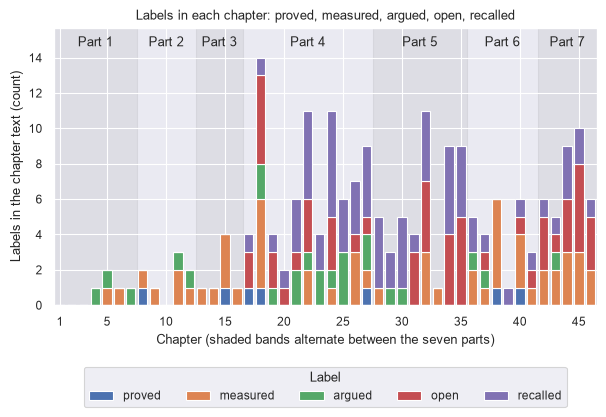

In [3]:
palette = sns.color_palette("deep")[:5]
figure, axis = plt.subplots(figsize=(7, 3.6))
chapters = list(range(1, LAST_CHAPTER + 1))
bottoms = [0] * LAST_CHAPTER
for label, colour in zip(LABELS, palette):
    axis.bar(chapters, COUNTS[label], bottom=bottoms, color=colour, label=label, width=0.8)
    bottoms = [bottom + count for bottom, count in zip(bottoms, COUNTS[label])]

part_edges = [start - 0.5 for start in PART_STARTS] + [LAST_CHAPTER + 0.5]
top = max(bottoms) * 1.12
for index in range(len(PART_STARTS)):
    if index % 2 == 0:
        axis.axvspan(part_edges[index], part_edges[index + 1], color="grey", alpha=0.12, zorder=0)
    axis.text((part_edges[index] + part_edges[index + 1]) / 2, top * 0.97, f"Part {index + 1}", ha="center", va="top")
axis.set_ylim(0, top)
axis.set_xlim(0.5, LAST_CHAPTER + 0.5)
axis.set_xticks([1] + list(range(5, LAST_CHAPTER + 1, 5)))
axis.set_xlabel("Chapter (shaded bands alternate between the seven parts)")
axis.set_ylabel("Labels in the chapter text (count)")
axis.set_title("Labels in each chapter: proved, measured, argued, open, recalled")
axis.legend(title="Label", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=5)
save_figure(figure, "47-labels-by-chapter")
plt.show()

In [4]:
for label in LABELS:
    chapter_with_most = chapters[COUNTS[label].index(max(COUNTS[label]))]
    print(f"{label}: total {sum(COUNTS[label])}, most in chapter {chapter_with_most} ({max(COUNTS[label])})")

proved: total 7, most in chapter 8 (1)
measured: total 54, most in chapter 18 (5)
argued: total 24, most in chapter 25 (3)
open: total 53, most in chapter 18 (5)
recalled: total 68, most in chapter 24 (6)
